# Clothing Image Classification: A Controlled Learning-Rate Experiment

**AI Foundations (Edward Hickman)**  
Project 4 — Deep Learning Systems

**Task:** supervised image classification using a convolutional neural network
(CNN) in PyTorch. Fashion-MNIST contains real product images, not generated
images, and was not used in the Titanic, student-performance or bike-rental
capstones. This is an educational benchmark, not a deployed retail system.

Read `EXPERIMENT_PLAN.md` for the choices committed before image download or
training. Replit AI assisted with planning, code, verification and writing;
the learner must review and understand the work and follow course AI-use rules.
Run every cell from the directory containing this notebook. The four original
compressed data files are included; if absent, the loader downloads checksum-
verified copies from a pinned revision of the dataset author's repository.

In [1]:
from copy import deepcopy
import gzip
import hashlib
import json
from pathlib import Path
import platform
import random
import struct
import time
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from torch import nn
from IPython.display import display

ROOT = Path.cwd()
DATA = ROOT / "data"
OUT = ROOT / "outputs"
DATA.mkdir(exist_ok=True)
OUT.mkdir(exist_ok=True)
SEED = 20261119
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)
torch.use_deterministic_algorithms(True)
device = torch.device("cpu")
print("CUDA available:", torch.cuda.is_available())
print("Experiment device:", device, "; deterministic CPU, two threads")
versions = {name: value for name, value in [
    ("python", platform.python_version()), ("torch", torch.__version__),
    ("numpy", np.__version__), ("pandas", pd.__version__),
    ("device", str(device)), ("torch_threads", torch.get_num_threads())]}
(OUT / "runtime_versions.json").write_text(json.dumps(versions, indent=2) + "\n")
display(pd.Series(versions, name="Executed runtime"))
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

CUDA available: False
Experiment device: cpu ; deterministic CPU, two threads


python              3.11.18
torch            2.15.0+cpu
numpy                 2.4.6
pandas                3.1.1
device                  cpu
torch_threads             2
Name: Executed runtime, dtype: object

## 1. Load, inspect and audit the original images

Xiao et al. (2017) describe 60,000 training and 10,000 test images, 28 × 28
pixels each, with ten equally sized categories. Source and label dictionary:
https://github.com/zalandoresearch/fashion-mnist. The source repository publishes
MD5 fingerprints; SHA-256 fingerprints are also saved for this exact copy.
The dataset's MIT notice is retained in `data/LICENSE.fashion-mnist`.

Headers, lengths, label counts, ranges and exact pixel repetitions are checked
before modeling. Pixel equality is not proof that two files represent the same
physical garment. We preserve the official benchmark, report cross-partition
matches and do not claim a product-independent or duplicate-free evaluation.

In [2]:
REVISION = "b2617bb6d3ffa2e429640350f613e3291e10b141"
BASE_URL = f"https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/{REVISION}/data/fashion/"
FILES = {
    "train-images-idx3-ubyte.gz": "8d4fb7e6c68d591d4c3dfef9ec88bf0d",
    "train-labels-idx1-ubyte.gz": "25c81989df183df01b3e8a0aad5dffbe",
    "t10k-images-idx3-ubyte.gz": "bef4ecab320f06d8554ea6380940ec79",
    "t10k-labels-idx1-ubyte.gz": "bb300cfdad3c16e7a12a480ee83cd310",
}
manifest = {}
for filename, expected in FILES.items():
    path = DATA / filename
    if not path.exists():
        print("Downloading", filename)
        urllib.request.urlretrieve(BASE_URL + filename, path)
    raw = path.read_bytes()
    assert hashlib.md5(raw).hexdigest() == expected, f"Source checksum mismatch: {filename}"
    manifest[filename] = {"bytes": len(raw), "md5": expected,
                          "sha256": hashlib.sha256(raw).hexdigest(),
                          "url": BASE_URL + filename}
(OUT / "dataset_manifest.json").write_text(json.dumps(manifest, indent=2) + "\n")

def read_images(filename):
    raw = gzip.decompress((DATA / filename).read_bytes())
    magic, n, h, w = struct.unpack(">IIII", raw[:16])
    assert magic == 2051 and (h, w) == (28, 28)
    assert len(raw) == 16 + n * h * w
    return np.frombuffer(raw, dtype=np.uint8, offset=16).reshape(n, h, w).copy()

def read_labels(filename):
    raw = gzip.decompress((DATA / filename).read_bytes())
    magic, n = struct.unpack(">II", raw[:8])
    assert magic == 2049 and len(raw) == 8 + n
    return np.frombuffer(raw, dtype=np.uint8, offset=8).copy()

images = read_images("train-images-idx3-ubyte.gz")
labels = read_labels("train-labels-idx1-ubyte.gz")
test_images = read_images("t10k-images-idx3-ubyte.gz")
test_labels = read_labels("t10k-labels-idx1-ubyte.gz")
CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
           "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
assert images.shape == (60000, 28, 28) and labels.shape == (60000,)
assert test_images.shape == (10000, 28, 28) and test_labels.shape == (10000,)
assert np.array_equal(np.bincount(labels), np.full(10, 6000))
assert np.array_equal(np.bincount(test_labels), np.full(10, 1000))
display(pd.DataFrame([
    {"source": "official training", "shape": str(images.shape),
     "dtype": str(images.dtype), "minimum": int(images.min()), "maximum": int(images.max())},
    {"source": "official test", "shape": str(test_images.shape),
     "dtype": str(test_images.dtype), "minimum": int(test_images.min()),
     "maximum": int(test_images.max())}]))
display(pd.DataFrame({"class_id": range(10), "label": CLASSES,
                     "official_training_n": np.bincount(labels),
                     "official_test_n": np.bincount(test_labels)}))

,source,shape,dtype,minimum,maximum
0,official training,"(60000, 28, 28)",uint8,0,255
1,official test,"(10000, 28, 28)",uint8,0,255


,class_id,label,official_training_n,official_test_n
0,0,T-shirt/top,6000,1000
1,1,Trouser,6000,1000
2,2,Pullover,6000,1000
3,3,Dress,6000,1000
4,4,Coat,6000,1000
5,5,Sandal,6000,1000
6,6,Shirt,6000,1000
7,7,Sneaker,6000,1000
8,8,Bag,6000,1000
9,9,Ankle boot,6000,1000


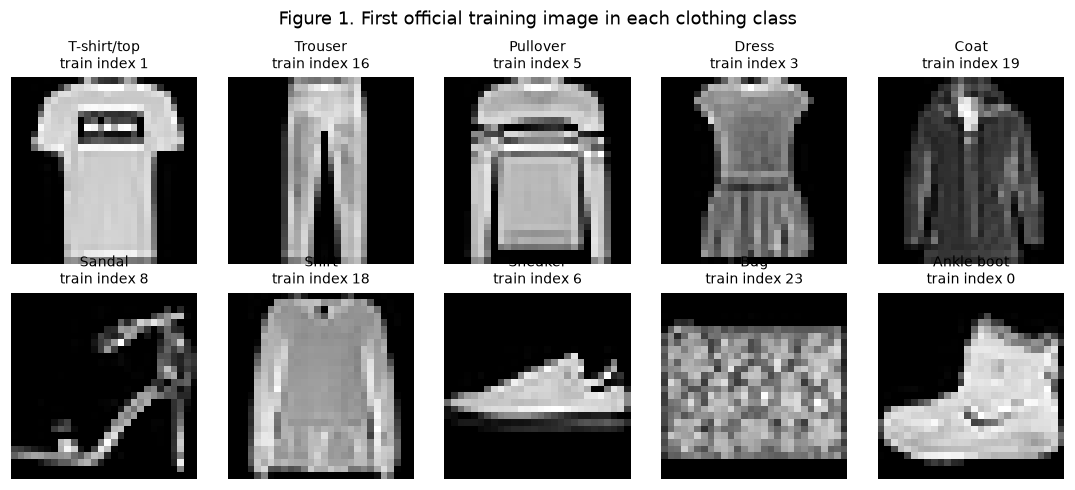

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
sample_indices = []
for class_id, ax in enumerate(axes.flat):
    index = int(np.flatnonzero(labels == class_id)[0])
    sample_indices.append(index)
    ax.imshow(images[index], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{CLASSES[class_id]}\ntrain index {index}", fontsize=9)
    ax.axis("off")
fig.suptitle("Figure 1. First official training image in each clothing class")
fig.tight_layout()
fig.savefig(OUT / "figure_1_training_examples.png", bbox_inches="tight")
plt.show()

## 2. Fixed splits and preprocessing

Only the official training set supplies training and validation records:
5,000 / 1,000 per class, chosen with seed 20261119. No test image affects
gradient updates, learning-rate choices or epoch selection. Looking at test
labels here checks the documented file structure and class counts, not model
performance. Original image indices and partition hashes make split identity
inspectable.

Pixels become float32 in [0,1] by dividing by 255, with shape N × 1 × 28 × 28.
There is no estimated mean/variance, imputation, augmentation or label encoding
fit on held-out images. Integer labels become `torch.int64`. Exact pixel
matches are counted across partitions; they are a disclosed evaluation risk.

In [4]:
rng = np.random.default_rng(SEED)
train_parts, val_parts = [], []
for class_id in range(10):
    shuffled = rng.permutation(np.flatnonzero(labels == class_id))
    val_parts.append(shuffled[:1000])
    train_parts.append(shuffled[1000:])
train_idx = np.sort(np.concatenate(train_parts))
val_idx = np.sort(np.concatenate(val_parts))
assert len(np.intersect1d(train_idx, val_idx)) == 0
assert len(np.union1d(train_idx, val_idx)) == 60000
split = np.full(60000, "train", dtype="<U10")
split[val_idx] = "validation"
assignments = pd.concat([
    pd.DataFrame({"source": "official_training", "source_index": np.arange(60000),
                  "class_id": labels, "split": split}),
    pd.DataFrame({"source": "official_test", "source_index": np.arange(10000),
                  "class_id": test_labels, "split": "test"})], ignore_index=True)
assignments.to_csv(OUT / "split_assignments.csv", index=False)
display(pd.crosstab(assignments.class_id, assignments.split).rename(index=dict(enumerate(CLASSES))))

def pixel_hashes(array):
    return [hashlib.sha256(image.tobytes()).hexdigest() for image in array]

development_hashes = np.array(pixel_hashes(images))
test_hashes = np.array(pixel_hashes(test_images))
train_hashes = set(development_hashes[train_idx])
val_hashes = set(development_hashes[val_idx])
all_development_hashes = set(development_hashes)
audit = {
    "training_images": len(train_idx), "validation_images": len(val_idx),
    "test_images": len(test_images), "missing_pixels": 0,
    "official_training_repeated_pixel_rows": 60000 - len(all_development_hashes),
    "official_test_repeated_pixel_rows": 10000 - len(set(test_hashes)),
    "validation_images_matching_training_pixels": sum(h in train_hashes for h in development_hashes[val_idx]),
    "test_images_matching_training_pixels": sum(h in train_hashes for h in test_hashes),
    "test_images_matching_validation_pixels": sum(h in val_hashes for h in test_hashes),
    "test_images_matching_official_training_pixels": sum(h in all_development_hashes for h in test_hashes),
    "train_indices_sha256": hashlib.sha256(train_idx.astype("<i8").tobytes()).hexdigest(),
    "validation_indices_sha256": hashlib.sha256(val_idx.astype("<i8").tobytes()).hexdigest(),
}
(OUT / "data_audit.json").write_text(json.dumps(audit, indent=2) + "\n")
display(pd.Series(audit, name="Data audit"))
x_train = torch.from_numpy(images[train_idx]).unsqueeze(1).float() / 255
y_train = torch.from_numpy(labels[train_idx].astype(np.int64))
x_val = torch.from_numpy(images[val_idx]).unsqueeze(1).float() / 255
y_val = torch.from_numpy(labels[val_idx].astype(np.int64))
x_test = torch.from_numpy(test_images).unsqueeze(1).float() / 255
y_test = torch.from_numpy(test_labels.astype(np.int64))
print("Training tensors:", x_train.shape, x_train.dtype, y_train.shape, y_train.dtype)
assert torch.isfinite(x_train).all() and x_train.min() == 0 and x_train.max() == 1

split,test,train,validation
class_id,,,
T-shirt/top,1000,5000,1000
Trouser,1000,5000,1000
Pullover,1000,5000,1000
Dress,1000,5000,1000
Coat,1000,5000,1000
Sandal,1000,5000,1000
Shirt,1000,5000,1000
Sneaker,1000,5000,1000
Bag,1000,5000,1000


training_images                                                                              50000
validation_images                                                                            10000
test_images                                                                                  10000
missing_pixels                                                                                   0
official_training_repeated_pixel_rows                                                            0
official_test_repeated_pixel_rows                                                                0
validation_images_matching_training_pixels                                                       0
test_images_matching_training_pixels                                                             0
test_images_matching_validation_pixels                                                           0
test_images_matching_official_training_pixels                                                    0
train_indi

Training tensors: torch.Size([50000, 1, 28, 28]) torch.float32 torch.Size([50000]) torch.int64


## 3. Baseline architecture and the one-variable comparison

CNNs fit image inputs because their layers learn visual representations
(LeCun et al., 2015). This deliberately small network applies two 3 × 3
convolutions, ReLU activations and 2 × 2 max pooling, followed by a 64-unit
hidden layer and ten output logits. Pooling reduces 28 → 14 → 7, so flattening
produces 16 × 7 × 7 = 784 values. ReLU introduces nonlinearity; the raw logits
feed `CrossEntropyLoss`, which expects unnormalized class scores and integer
labels (PyTorch contributors, n.d.-b). There is no softmax before the loss.

**Exactly one major aspect changes: Adam learning rate 0.001 → 0.0003.**
Adam's default 0.001 is a documented baseline, not an established optimum
(PyTorch contributors, n.d.-a). The smaller value tests smaller updates under
the same five-epoch budget. Both models have identical architecture, initial
weights, training orders, batch size 128, loss and all other optimizer settings.
Five epochs and this small width are resource-bounded choices, not tuned
hyperparameters. No dropout, scheduler, augmentation, early stopping or
validation-based checkpoint selection is used. Both final epoch-five models
are evaluated. A single controlled run per configuration tests this setup,
not the distribution of results across random seeds.

In [5]:
class ClothingCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(1, 8, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(8, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(), nn.Linear(16 * 7 * 7, 64), nn.ReLU(), nn.Linear(64, 10))

    def forward(self, x):
        return self.layers(x)

shared = {"epochs": 5, "batch_size": 128, "optimizer": "Adam",
          "betas": [0.9, 0.999], "eps": 1e-8, "weight_decay": 0,
          "amsgrad": False, "foreach": False, "seed": SEED,
          "device": "cpu", "threads": 2, "checkpoint": "final_epoch"}
configs = {name: {**shared, "learning_rate": rate}
           for name, rate in [("baseline", 0.001), ("experimental", 0.0003)]}
changed_keys = [key for key in configs["baseline"]
                if configs["baseline"][key] != configs["experimental"][key]]
assert changed_keys == ["learning_rate"]
(OUT / "experiment_configs.json").write_text(json.dumps(configs, indent=2) + "\n")
torch.manual_seed(SEED)
initial_model = ClothingCNN().to(device)
initial_state = deepcopy(initial_model.state_dict())
parameter_count = sum(p.numel() for p in initial_model.parameters())

def state_hash(state):
    digest = hashlib.sha256()
    for key, tensor in state.items():
        digest.update(key.encode())
        digest.update(tensor.detach().cpu().numpy().tobytes())
    return digest.hexdigest()

initial_hash = state_hash(initial_state)
print(initial_model)
print("Trainable parameters:", parameter_count)
print("Output shape:", initial_model(x_train[:2]).shape)
display(pd.DataFrame(configs).T)

ClothingCNN(
  (layers): Sequential(
    (0): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Flatten(start_dim=1, end_dim=-1)
    (7): Linear(in_features=784, out_features=64, bias=True)
    (8): ReLU()
    (9): Linear(in_features=64, out_features=10, bias=True)
  )
)
Trainable parameters: 52138


Output shape: torch.Size([2, 10])


,epochs,batch_size,optimizer,betas,eps,weight_decay,amsgrad,foreach,seed,device,threads,checkpoint,learning_rate
baseline,5,128,Adam,"[0.9, 0.999]",0.0,0,False,False,20261119,cpu,2,final_epoch,0.001
experimental,5,128,Adam,"[0.9, 0.999]",0.0,0,False,False,20261119,cpu,2,final_epoch,0.0003


## 4. Train both models and record every epoch

Gradient tracking is enabled only for training; evaluation uses `model.eval()`
and `torch.inference_mode()`. Loss totals are weighted by sample count, so the
last shorter batch is not given the weight of a full batch. Epoch training
metrics are online measurements while parameters change; validation metrics
are calculated after each epoch at fixed weights. They are therefore not
strictly identical measurement conditions.

Both configurations load the exact same initial state. Each epoch uses the
same seeded permutation for both runs, recorded with SHA-256; Adam is new for
each run. Deterministic algorithms and explicit seeds reduce variation on
this CPU/software stack, but do not guarantee identical results on different
hardware or PyTorch releases (PyTorch contributors, n.d.-c).

In [6]:
loss_fn = nn.CrossEntropyLoss()
history, controls, durations, trained = [], {}, {}, {}

def evaluate(model, x, y, batch_size=512):
    model.eval()
    total_loss, correct = 0.0, 0
    logits_parts = []
    with torch.inference_mode():
        for start in range(0, len(y), batch_size):
            xb, yb = x[start:start + batch_size], y[start:start + batch_size]
            logits = model(xb)
            total_loss += loss_fn(logits, yb).item() * len(yb)
            correct += int((logits.argmax(1) == yb).sum())
            logits_parts.append(logits)
    return total_loss / len(y), correct / len(y), torch.cat(logits_parts)

for name, config in configs.items():
    model = ClothingCNN().to(device)
    model.load_state_dict(deepcopy(initial_state))
    before = state_hash(model.state_dict())
    assert before == initial_hash
    optimizer = torch.optim.Adam(
        model.parameters(), lr=config["learning_rate"], betas=tuple(config["betas"]),
        eps=config["eps"], weight_decay=config["weight_decay"],
        amsgrad=config["amsgrad"], foreach=config["foreach"])
    orders = []
    started = time.perf_counter()
    for epoch in range(1, config["epochs"] + 1):
        generator = torch.Generator().manual_seed(SEED + epoch)
        order = torch.randperm(len(y_train), generator=generator)
        orders.append(hashlib.sha256(order.numpy().astype("<i8").tobytes()).hexdigest())
        model.train()
        total_loss, correct = 0.0, 0
        for indices in order.split(config["batch_size"]):
            xb, yb = x_train[indices], y_train[indices]
            optimizer.zero_grad(set_to_none=True)
            logits = model(xb)
            loss = loss_fn(logits, yb)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(yb)
            correct += int((logits.detach().argmax(1) == yb).sum())
        val_loss, val_accuracy, _ = evaluate(model, x_val, y_val)
        row = {"model": name, "epoch": epoch,
               "train_loss": total_loss / len(y_train),
               "train_accuracy": correct / len(y_train),
               "validation_loss": val_loss, "validation_accuracy": val_accuracy}
        history.append(row)
        print(f"{name} epoch {epoch}: train loss {row['train_loss']:.4f}, "
              f"validation loss {val_loss:.4f}, validation accuracy {val_accuracy:.2%}", flush=True)
    durations[name] = time.perf_counter() - started
    controls[name] = {"initial_state_sha256": before, "epoch_order_sha256": orders,
                      "final_state_sha256": state_hash(model.state_dict())}
    trained[name] = model
    torch.save(model.state_dict(), OUT / f"{name}_state.pt")
assert controls["baseline"]["initial_state_sha256"] == controls["experimental"]["initial_state_sha256"]
assert controls["baseline"]["epoch_order_sha256"] == controls["experimental"]["epoch_order_sha256"]
history = pd.DataFrame(history)
history.to_csv(OUT / "training_history.csv", index=False)
(OUT / "control_audit.json").write_text(json.dumps(controls, indent=2) + "\n")
(OUT / "training_seconds.json").write_text(json.dumps(durations, indent=2) + "\n")
display(history)
display(pd.Series(durations, name="Training plus validation seconds (this run)"))

baseline epoch 1: train loss 0.7728, validation loss 0.4904, validation accuracy 82.67%


baseline epoch 2: train loss 0.4497, validation loss 0.4086, validation accuracy 85.69%


baseline epoch 3: train loss 0.3946, validation loss 0.3934, validation accuracy 85.87%


baseline epoch 4: train loss 0.3621, validation loss 0.3607, validation accuracy 87.30%


baseline epoch 5: train loss 0.3410, validation loss 0.3305, validation accuracy 88.13%


experimental epoch 1: train loss 1.0646, validation loss 0.6303, validation accuracy 77.04%


... (2 outputs left out)

experimental epoch 4: train loss 0.4557, validation loss 0.4433, validation accuracy 83.81%


experimental epoch 5: train loss 0.4278, validation loss 0.4114, validation accuracy 85.22%


,model,epoch,train_loss,train_accuracy,validation_loss,validation_accuracy
0,baseline,1,0.772775,0.72182,0.490440,0.8267
1,baseline,2,0.449735,0.83752,0.408599,0.8569
2,baseline,3,0.394592,0.85808,0.393400,0.8587
3,baseline,4,0.362092,0.87104,0.360665,0.8730
4,baseline,5,0.341036,0.87704,0.330473,0.8813
5,experimental,1,1.064627,0.64924,0.630320,0.7704
6,experimental,2,0.564987,0.79284,0.528020,0.8080
7,experimental,3,0.495119,0.81954,0.477024,0.8252
8,experimental,4,0.455700,0.83690,0.443287,0.8381
9,experimental,5,0.427808,0.84724,0.411396,0.8522


baseline        18.553069
experimental    17.523762
Name: Training plus validation seconds (this run), dtype: float64

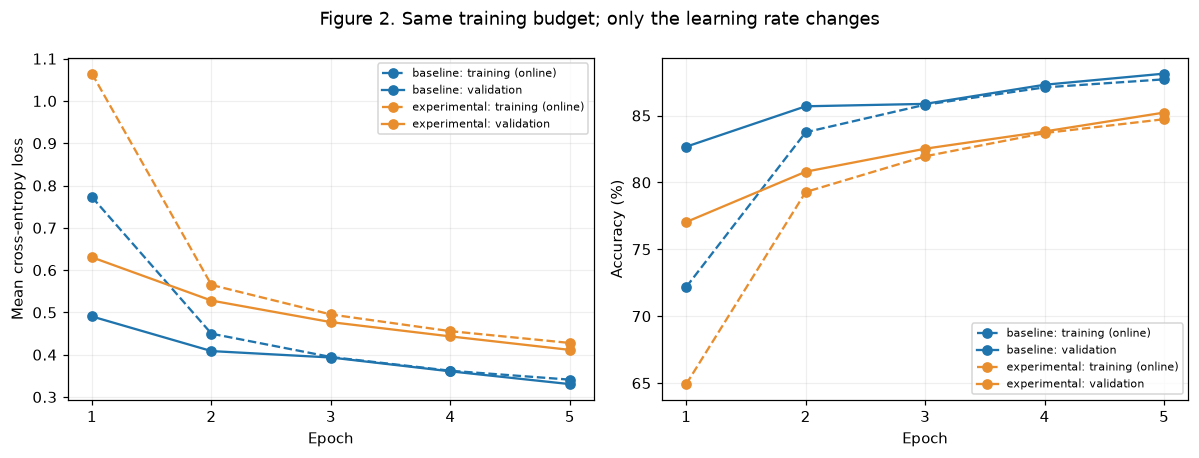

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for name, color in [("baseline", "#1F74AD"), ("experimental", "#E98E2E")]:
    rows = history[history.model == name]
    for prefix, linestyle, caption in [("train", "--", "training (online)"),
                                      ("validation", "-", "validation")]:
        axes[0].plot(rows.epoch, rows[f"{prefix}_loss"], color=color,
                     linestyle=linestyle, marker="o", label=f"{name}: {caption}")
        axes[1].plot(rows.epoch, rows[f"{prefix}_accuracy"] * 100, color=color,
                     linestyle=linestyle, marker="o", label=f"{name}: {caption}")
axes[0].set(ylabel="Mean cross-entropy loss", xlabel="Epoch")
axes[1].set(ylabel="Accuracy (%)", xlabel="Epoch")
for ax in axes:
    ax.set_xticks(range(1, 6))
    ax.legend(fontsize=7)
    ax.grid(alpha=0.2)
fig.suptitle("Figure 2. Same training budget; only the learning rate changes")
fig.tight_layout()
fig.savefig(OUT / "figure_2_learning_curves.png", bbox_inches="tight")
plt.show()

## 5. Evaluate both final models on the official test set

Accuracy is the share of correct top-one labels and is meaningful for this
balanced ten-class benchmark. A confusion matrix and per-class recall expose
mistakes hidden by that overall average. Macro-F1 averages each class's
precision/recall balance with equal class weight; zero denominators receive
zero. Cross-entropy also considers the scores assigned to the true labels
(PyTorch contributors, n.d.-b). Definitions are implemented explicitly below.
Softmax scores sum to one but are not certified confidence or calibrated
probabilities.

Test evaluation occurs only after both models finish training; no learning
rate or checkpoint is chosen using test performance. The experiment retains
all predictions and both confusion matrices, not only the better-looking
outcome. No statistical significance or multi-seed robustness is claimed.

In [8]:
def classification_metrics(y_true, y_pred):
    cm = np.zeros((10, 10), dtype=np.int64)
    np.add.at(cm, (y_true, y_pred), 1)
    tp = np.diag(cm).astype(float)
    precision = np.divide(tp, cm.sum(0), out=np.zeros(10), where=cm.sum(0) != 0)
    recall = np.divide(tp, cm.sum(1), out=np.zeros(10), where=cm.sum(1) != 0)
    f1 = np.divide(2 * precision * recall, precision + recall,
                   out=np.zeros(10), where=(precision + recall) != 0)
    return cm, precision, recall, f1

metrics, matrices, prediction_frames, class_frames = [], {}, [], []
for name, model in trained.items():
    test_loss, test_accuracy, logits = evaluate(model, x_test, y_test)
    probability = logits.softmax(1).numpy()
    pred = logits.argmax(1).numpy()
    cm, precision, recall, f1 = classification_metrics(test_labels, pred)
    matrices[name] = cm
    last = history[history.model == name].iloc[-1]
    metrics.append({"model": name, "learning_rate": configs[name]["learning_rate"],
                    "validation_accuracy": float(last.validation_accuracy),
                    "validation_loss": float(last.validation_loss),
                    "test_accuracy": test_accuracy, "test_macro_f1": float(f1.mean()),
                    "test_loss": test_loss, "test_correct": int((pred == test_labels).sum()),
                    "test_errors": int((pred != test_labels).sum())})
    predictions = pd.DataFrame({
        "model": name, "test_index": np.arange(10000),
        "true_class": test_labels, "predicted_class": pred,
        "true_label": [CLASSES[i] for i in test_labels],
        "predicted_label": [CLASSES[i] for i in pred],
        "correct": pred == test_labels,
        "example_loss": nn.functional.cross_entropy(logits, y_test, reduction="none").numpy()})
    for class_id in range(10):
        predictions[f"probability_{class_id}"] = probability[:, class_id]
    prediction_frames.append(predictions)
    class_frames.append(pd.DataFrame({
        "model": name, "class_id": range(10), "label": CLASSES,
        "precision": precision, "recall": recall, "f1": f1, "support": cm.sum(1)}))
    pd.DataFrame(cm, index=CLASSES, columns=CLASSES).to_csv(OUT / f"{name}_confusion_matrix.csv")
metrics = pd.DataFrame(metrics)
predictions = pd.concat(prediction_frames, ignore_index=True)
per_class = pd.concat(class_frames, ignore_index=True)
metrics.to_csv(OUT / "model_metrics.csv", index=False)
predictions.to_csv(OUT / "test_predictions.csv", index=False)
per_class.to_csv(OUT / "per_class_metrics.csv", index=False)
display(metrics)
display(per_class)

,model,learning_rate,validation_accuracy,validation_loss,test_accuracy,test_macro_f1,test_loss,test_correct,test_errors
0,baseline,0.0010,0.8813,0.330473,0.8729,0.870471,0.356594,8729,1271
1,experimental,0.0003,0.8522,0.411396,0.8463,0.842950,0.434081,8463,1537


,model,class_id,label,precision,recall,f1,support
0,baseline,0,T-shirt/top,0.777580,0.874,0.822976,1000
1,baseline,1,Trouser,0.985656,0.962,0.973684,1000
2,baseline,2,Pullover,0.773358,0.836,0.803460,1000
3,baseline,3,Dress,0.862669,0.892,0.877089,1000
4,baseline,4,Coat,0.798762,0.774,0.786186,1000
5,baseline,5,Sandal,0.950437,0.978,0.964022,1000
6,baseline,6,Shirt,0.737255,0.564,0.639093,1000
7,baseline,7,Sneaker,0.942623,0.920,0.931174,1000
8,baseline,8,Bag,0.934928,0.977,0.955501,1000
9,baseline,9,Ankle boot,0.951049,0.952,0.951524,1000


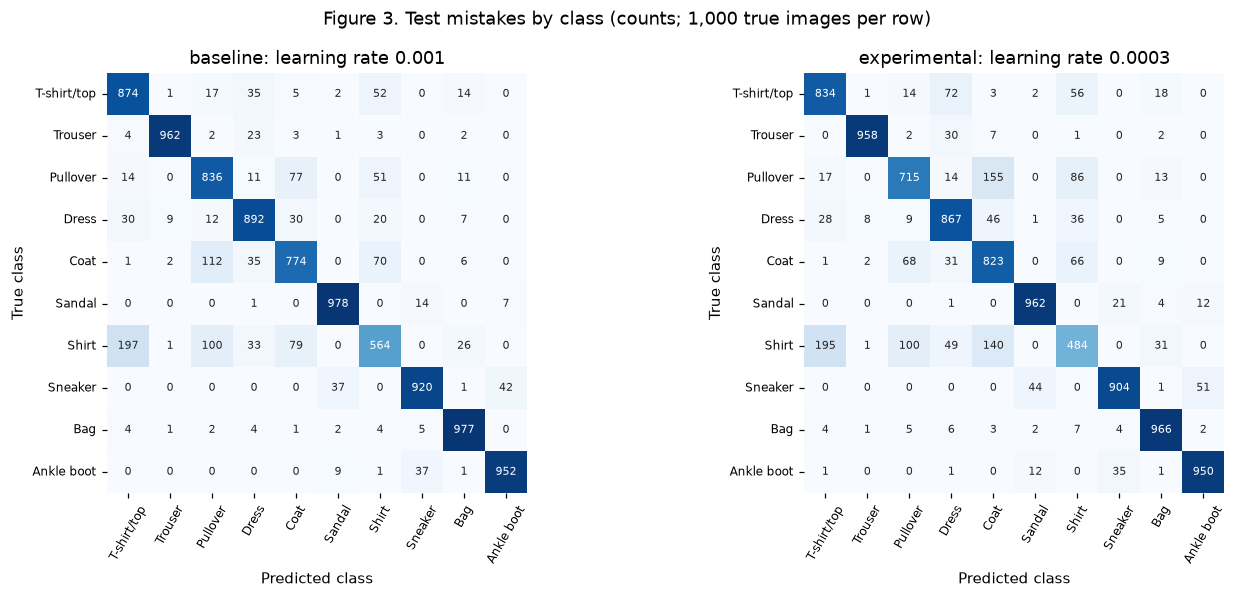

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, name in zip(axes, ["baseline", "experimental"]):
    sns.heatmap(matrices[name], annot=True, fmt="d", cmap="Blues",
                vmin=0, vmax=1000, cbar=False, square=True,
                xticklabels=CLASSES, yticklabels=CLASSES, ax=ax,
                annot_kws={"fontsize": 7})
    ax.set(title=f"{name}: learning rate {configs[name]['learning_rate']}",
           xlabel="Predicted class", ylabel="True class")
    ax.tick_params(axis="x", rotation=60, labelsize=8)
    ax.tick_params(axis="y", rotation=0, labelsize=8)
fig.suptitle("Figure 3. Test mistakes by class (counts; 1,000 true images per row)")
fig.tight_layout()
fig.savefig(OUT / "figure_3_confusion_matrices.png", bbox_inches="tight")
plt.show()

## 6. Inspect specific failures, not just the headline score

Figure 4 uses the **first eight baseline errors in original test-index order**,
not examples selected for visual impact. Both models' predictions are shown
on each identical input. These are errors relative to the provided dataset
labels; the inspection does not establish that every human label is
unambiguous. The complete prediction CSV lets a reviewer inspect other cases.

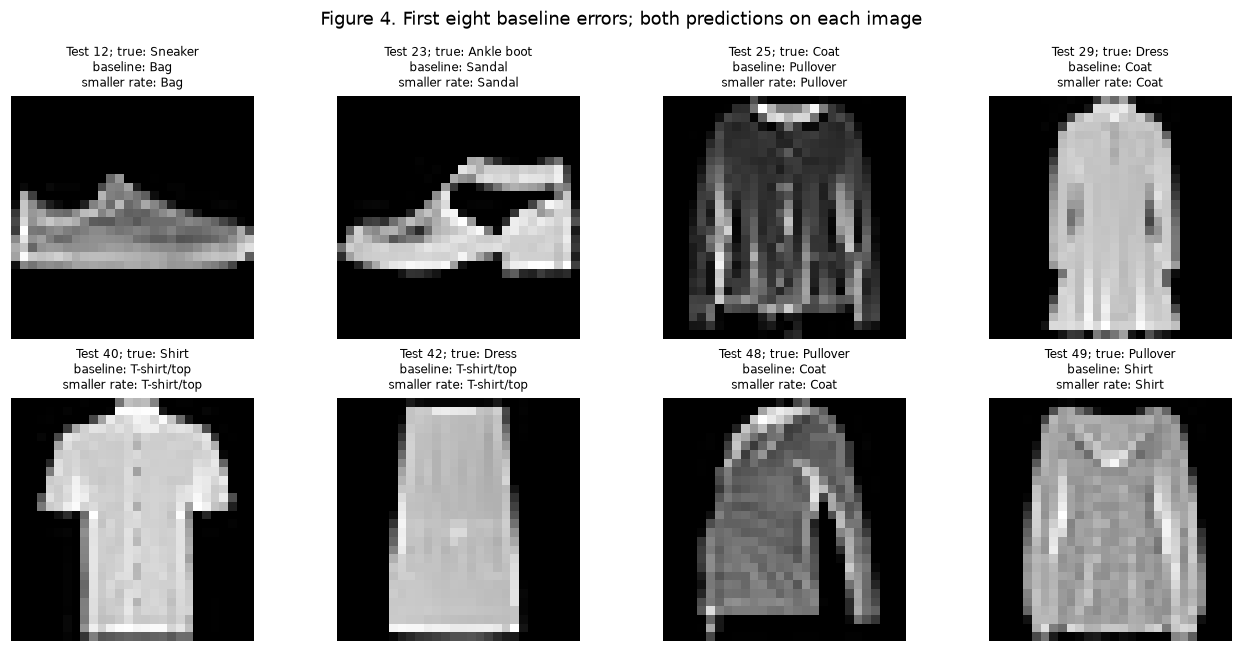

,test_index,true_label,baseline_label,experimental_label
0,12,Sneaker,Bag,Bag
1,23,Ankle boot,Sandal,Sandal
2,25,Coat,Pullover,Pullover
3,29,Dress,Coat,Coat
4,40,Shirt,T-shirt/top,T-shirt/top
5,42,Dress,T-shirt/top,T-shirt/top
6,48,Pullover,Coat,Coat
7,49,Pullover,Shirt,Shirt


{
  "task": "supervised image classification; PyTorch CNN",
  "seed": 20261119,
  "parameter_count": 52138,
  "changed_keys": [
    "learning_rate"
  ],
  "data_audit": {
    "training_images": 50000,
    "validation_images": 10000,
    "test_images": 10000,
    "missing_pixels": 0,
    "official_training_repeated_pixel_rows": 0,
    "official_test_repeated_pixel_rows": 0,
    "validation_images_matching_training_pixels": 0,
    "test_images_matching_training_pixels": 0,
    "test_images_matching_validation_pixels": 0,
    "test_images_matching_official_training_pixels": 0,
    "train_indices_sha256": "3f52f09672d4a23ea11f5b38fb6ce3b74f033c5faf3f7ab988bf0c0b7030c951",
    "validation_indices_sha256": "554355b2b21614f4090dbc7c37e04f84f7a8aac377c7ca169a2bf73573299fd6"
  },
  "models": {
    "baseline": {
      "learning_rate": 0.001,
      "validation_accuracy": 0.8813,
      "validation_loss": 0.33047322583198546,
      "test_accuracy": 0.8729,
      "test_macro_f1": 0.8704709682916919,

In [10]:
baseline_predictions = predictions[predictions.model == "baseline"].reset_index(drop=True)
experimental_predictions = predictions[predictions.model == "experimental"].reset_index(drop=True)
error_indices = baseline_predictions.loc[~baseline_predictions.correct, "test_index"].head(8).tolist()
assert error_indices, "No baseline errors available to illustrate"
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, index in zip(axes.flat, error_indices):
    a = baseline_predictions.iloc[index]
    b = experimental_predictions.iloc[index]
    ax.imshow(test_images[index], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Test {index}; true: {a.true_label}\n"
                 f"baseline: {a.predicted_label}\nsmaller rate: {b.predicted_label}", fontsize=8)
    ax.axis("off")
for ax in list(axes.flat)[len(error_indices):]:
    ax.axis("off")
fig.suptitle("Figure 4. First eight baseline errors; both predictions on each image")
fig.tight_layout()
fig.savefig(OUT / "figure_4_error_examples.png", bbox_inches="tight")
plt.show()
error_examples = pd.DataFrame([
    {"test_index": i, "true_label": baseline_predictions.iloc[i].true_label,
     "baseline_label": baseline_predictions.iloc[i].predicted_label,
     "experimental_label": experimental_predictions.iloc[i].predicted_label}
    for i in error_indices])
error_examples.to_csv(OUT / "error_examples.csv", index=False)
display(error_examples)
summary = {
    "task": "supervised image classification; PyTorch CNN",
    "seed": SEED, "parameter_count": parameter_count, "changed_keys": changed_keys,
    "data_audit": audit, "models": metrics.set_index("model").to_dict(orient="index"),
    "first_error": error_examples.iloc[0].to_dict(),
    "shown_error_indices": error_indices,
    "validation_accuracy_gap_baseline_minus_experimental": float(
        metrics.iloc[0].validation_accuracy - metrics.iloc[1].validation_accuracy),
    "test_accuracy_gap_baseline_minus_experimental": float(
        metrics.iloc[0].test_accuracy - metrics.iloc[1].test_accuracy)}
(OUT / "experiment_summary.json").write_text(json.dumps(summary, indent=2) + "\n")
print(json.dumps(summary, indent=2))

## Limitations, responsible use and next steps

Only the learning rate was varied; depth, training duration, initialization and
dataset choice were not experimentally optimized. One paired seed and five
epochs cannot establish which setting works best generally. No exact pixel
matches were found, but near-duplicate products or shared styles are not ruled
out; a single catalog and 28 × 28 grayscale preprocessing limit real-world
transfer. Neither official
partition proves separation by garment identity. Uncertainty across seeds,
calibration, new-retailer performance and demographic fairness were not tested.

The intended use is learning and benchmark comparison. A mislabel could place
a seller's product in the wrong search category and reduce its visibility.
Categories/styles absent from this catalog may be served poorly; class balance
does not establish fair treatment of sellers or customers. No demographic
attributes are provided, so none are inferred. Retain human correction and
audit performance on diverse, permissioned product images before any retail
use; document intended uses and limitations, following model-reporting guidance
(Mitchell et al., 2019). Do not repurpose this model for judging people.

Next, repeat the *same* paired comparison across seeds and report variability,
audit product-identity overlap if identifiers become available, and obtain an
independent color-photo dataset with permission. Compare longer fixed training
budgets separately from learning-rate changes; do not change multiple factors
and attribute all gains to one. Keep any new test set separate from tuning.

## Sources

- LeCun, Y., Bengio, Y., & Hinton, G. (2015). Deep learning. *Nature, 521*, 436–444.
  https://doi.org/10.1038/nature14539
- Mitchell, M., et al. (2019). Model cards for model reporting.
  https://doi.org/10.1145/3287560.3287596
- PyTorch contributors. (n.d.-a). *Adam*.
  https://docs.pytorch.org/docs/2.15/generated/torch.optim.Adam.html
- PyTorch contributors. (n.d.-b). *CrossEntropyLoss*.
  https://docs.pytorch.org/docs/2.15/generated/torch.nn.CrossEntropyLoss.html
- PyTorch contributors. (n.d.-c). *Reproducibility*.
  https://docs.pytorch.org/docs/2.15/notes/randomness.html
- Xiao, H., Rasul, K., & Vollgraf, R. (2017). *Fashion-MNIST: A novel image
  dataset for benchmarking machine learning algorithms* [Preprint]. arXiv.
  https://doi.org/10.48550/arXiv.1708.07747

## Notebook summary

This supervised image-classification experiment used all 70,000 real Fashion-MNIST clothing images, with 50,000 for training, 10,000 for validation and the official 10,000-image test set.
Two identical PyTorch CNNs started from the same weights and saw the same shuffled batches for five epochs; only Adam's learning rate changed from 0.001 to 0.0003.
The baseline achieved 87.29% test accuracy and 0.8705 macro-F1, compared with 84.63% and 0.8430 for the smaller-rate model, a signed accuracy change of -2.66 percentage points.
The first baseline error was test image 12, labeled Sneaker but predicted Bag; it illustrates why aggregate accuracy does not guarantee a correct clothing label for each image.
One seed, five epochs, untested garment-identity overlap and a single retailer's tiny grayscale images limit broader conclusions, so neither result establishes production readiness or a universally better learning rate.